# Bayesian Stochastic Volatility vs GARCH vs LSTM in R: Volatility Forecasts and VaR for Stocks, the Euro and Crude Oil

GARCH has been the workhorse of volatility forecasting for forty years. Stochastic volatility models are more flexible but harder to estimate, and neural networks promise to learn the patterns on their own. This notebook puts all three against each other on three very different markets and scores them out of sample on the quantity a risk manager actually uses: tomorrow's volatility and VaR.

**What it does.** It forecasts tomorrow's volatility of three very different assets with three model families, and scores them out of sample from 2012:

- the S&P 500 (SPY), with strong leverage effects;
- EUR/USD, a calm and nearly symmetric market;
- WTI crude oil, with jumps and regime changes.

The models:

1. a **Bayesian stochastic volatility** model (`stochvol`, MCMC), where volatility is a latent random process. Its parameters are re-estimated by MCMC, and the latent volatility is tracked daily with a **particle filter** written from scratch;
2. **GJR-GARCH(1,1)** with Student-t errors (`rugarch`), the industry workhorse;
3. an **LSTM** in R's native `torch`, trained by maximum likelihood on the last 22 days of returns.

An EWMA (RiskMetrics) forecast is the benchmark.

**Data.** Yahoo Finance via `quantmod` (SPY) and FRED (EUR/USD noon rate, WTI spot), daily since 2005.

**Methods.** `stochvol` MCMC with posterior credible bands, a bootstrap particle filter, `rugarch` with periodic re-estimation and daily filtering, and a `torch` LSTM with a Gaussian log-likelihood loss.

Forecasts are compared with QLIKE and MSE losses and Diebold–Mariano tests, and the VaR with 99% backtests.

**Key output.** Posterior volatility with its uncertainty, the persistence and volatility of volatility of each asset, forecast losses by model, and VaR exception rates.

## 1. Two ways to model volatility, and a third that learns it

**GARCH** makes today's variance a deterministic function of yesterday's squared return and variance: σ²_t = ω + (α + γ·1[r<0])·r²_{t−1} + β·σ²_{t−1}. Volatility is known one step ahead, and estimation is fast and exact by maximum likelihood.

**Stochastic volatility** (Taylor, 1986; Jacquier, Polson and Rossi, 1994) treats log-variance as its own random process:

r_t = exp(h_t / 2)·ε_t,  h_t = μ + φ·(h_{t−1} − μ) + σ_η·η_t

A shock to volatility is not the same thing as a large return. This is more flexible, and it often fits better, but the likelihood has no closed form: the latent path must be integrated out, so estimation is Bayesian (MCMC) and filtering needs simulation (particle filters). `stochvol` (Kastner, 2016) uses an efficient ancillarity–sufficiency interweaving sampler.

**An LSTM** makes no structural assumption: it reads a window of recent returns and outputs a log-variance, trained to maximise the Gaussian likelihood of the next return. With enough data it could learn asymmetry, long memory and regime effects on its own.

Forecasts are scored with **QLIKE**, L = r²/σ̂² − log(r²/σ̂²) − 1. Patton (2011) shows QLIKE is robust to using the noisy squared return as a proxy for true variance, and it penalises under-prediction of risk more than over-prediction.

## 2. Setup

In [1]:
# --- Packages (install once with `Rscript install_packages.R` from the repo
# root)
suppressPackageStartupMessages({
  library(tidyverse)
  library(scales)
  library(patchwork)
  library(plotly)
  library(htmlwidgets)
  library(jsonlite)
})
options(warn = 1, dplyr.summarise.inform = FALSE, repr.plot.width = 14,
        repr.plot.height = 5, repr.plot.res = 110)
# plain-text tables in the notebook (no ANSI colour codes)
options(crayon.enabled = FALSE, cli.num_colors = 1)

# --- Folders and credentials
PROJECT_DIR <- getwd()
DATA_DIR <- file.path(PROJECT_DIR,
                      "data"); OUT_DIR <- file.path(PROJECT_DIR, "outputs")
dir.create(DATA_DIR,
           showWarnings = FALSE); dir.create(OUT_DIR, showWarnings = FALSE)
# look for .env in this folder and its parents (like python-dotenv)
find_env <- function(start = getwd()) {
  d <- normalizePath(start)
  repeat {
    f <- file.path(d, ".env")
    if (file.exists(f)) return(f)
    parent <- dirname(d)
    if (parent == d) return(NA_character_)
    d <- parent
  }
}
env_file <- find_env()
# tolerate a missing final newline
if (!is.na(env_file)) suppressWarnings(dotenv::load_dot_env(env_file))

# --- Cache helper: every download is stored in data/ and reused for 12 hours
cached <- function(name, fetch, max_age_hours = 12) {
  path <- file.path(DATA_DIR, paste0(name, ".rds"))
  if (file.exists(path) &&
      difftime(Sys.time(), file.mtime(path),
               units = "hours") < max_age_hours) return(readRDS(path))
  out <- tryCatch(fetch(), error = function(e) {
    if (file.exists(path)) { message(name, ": download failed (",
                                     conditionMessage(e),
                                     "); using cached copy"); return(readRDS(path)) }
    stop(e)
  })
  saveRDS(out, path)
  out
}

# --- Chart style (consistent palette across all charts)
PALETTE <- c("#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300",
             "#6250d6", "#e34948")
INK <- "#0b0b0b"; INK_2 <- "#52514e"; GRID <- "#e4e3df"; SURFACE <- "#fcfcfb"
STATUS <- c(green = "#1baf7a", amber = "#eda100", red = "#e34948")
theme_risk <- function() {
  theme_minimal(base_size = 11) +
    theme(plot.background = element_rect(fill = SURFACE, colour = NA),
          panel.background = element_rect(fill = SURFACE, colour = NA),
          panel.grid.major = element_line(colour = GRID),
            panel.grid.minor = element_blank(),
          plot.title = element_text(face = "bold", colour = INK, size = 12),
            plot.title.position = "plot",
          axis.text = element_text(colour = INK_2),
            axis.title = element_text(colour = INK_2),
          legend.position = "top", legend.title = element_blank())
}
theme_set(theme_risk())
save_fig <- function(p, name, width = 14,
                     height = 5) ggsave(file.path(
                         OUT_DIR, paste0(name, ".png")),
                                        p, width = width, height = height,
                                        dpi = 150, bg = SURFACE)

# Interactive dashboard as a single HTML file that loads plotly.js from a CDN
# (no pandoc needed)
save_plotly_html <- function(widget, name, title) {
  b <- plotly_build(widget)$x
  if (is.null(b$layout$height)) b$layout$height <- 900
  html <- sprintf('<!doctype html><html><head><meta charset="utf-8"><title>%s</title>
<script src="https://cdn.plot.ly/plotly-2.35.2.min.js"></script></head>
<body style="background:%s;margin:0"><div id="dash" style="width:100%%;height:95vh"></div>
<script>var fig=%s;Plotly.newPlot("dash",fig.data,fig.layout,{responsive:true});</script></body></html>',
                  title, SURFACE,
                    toJSON(list(data = b$data, layout = b$layout),
                           auto_unbox = TRUE, null = "null", na = "null",
                           force = TRUE, digits = NA))
  writeLines(html, file.path(OUT_DIR, paste0(name, ".html")))
  message("Dashboard saved: outputs/", name, ".html")
}

suppressPackageStartupMessages({
  library(quantmod)
  library(fredr)
  library(rugarch)
  library(stochvol)
  library(torch)
})
if (Sys.getenv("FRED_API_KEY") == "") stop("FRED_API_KEY not found: create the .env file at the repo root")
fredr_set_key(Sys.getenv("FRED_API_KEY"))
if (!torch_is_installed()) stop("Run torch::install_torch() once (or Rscript install_packages.R), then restart the kernel")
START <- as.Date("2005-01-01"); OOS_START <- as.Date("2012-01-01")
# trading days between re-estimations
REFIT_SV <- 126; REFIT_GARCH <- 63; REFIT_NN <- 252
SV_DRAWS <- 3000; SV_BURN <- 1000; N_PART <- 3000; LOOKBACK <- 22
set.seed(8); torch_manual_seed(8)
cat(sprintf("R %s · stochvol %s · rugarch %s · torch %s · run on %s\n",
            getRversion(), packageVersion("stochvol"),
            packageVersion("rugarch"),
            packageVersion("torch"), Sys.Date()))

R 4.3.3 · stochvol 3.2.9 · rugarch 1.5.6 · torch 0.17.0 · run on 2026-10-21


## 3. Data

Daily log returns in percent, on each asset's own trading calendar:
- **SPY:** adjusted closes;
- **EUR/USD:** the Federal Reserve's noon buying rate (`DEXUSEU`);
- **WTI:** the Cushing spot price (`DCOILWTICO`). Non-positive prices (20 April 2020) are removed, and the single largest absolute daily return is capped at 40% so that one print does not dominate every loss function.

Each series is demeaned with its training-window mean before modelling.

In [2]:
spy <- cached("spy",
  function() Ad(getSymbols("SPY", src = "yahoo", from = START,
                           auto.assign = FALSE)),
  max_age_hours = 24
)
fred_x <- function(id) {
  d <- fredr(series_id = id, observation_start = START); x <- xts(
    d$value,
    d$date
  ); x[!is.na(x) & x > 0]
}
eur <- cached("eurusd", function() fred_x("DEXUSEU"), max_age_hours = 24)
wti <- cached("wti", function() fred_x("DCOILWTICO"), max_age_hours = 24)
mk <- function(p) {
  r <- 100 * na.omit(diff(log(p))); r[abs(r) > 40] <- sign(r[abs(r) > 40]) *
    40; r[index(r) < Sys.Date()]
}
RET <- list(
  `S&P 500 (SPY)` = mk(spy), `EUR/USD` = mk(eur),
  `WTI crude` = mk(wti)
)
map_dfr(names(RET), function(a) {
  r <- as.numeric(RET[[a]]); tibble(
    asset = a, days = length(r), from = first(index(RET[[a]])),
    to = last(index(RET[[a]])),
    `vol (% p.a.)` = sd(r) * sqrt(252), skewness = mean((r - mean(r))^3) /
      sd(r)^3, `excess kurtosis` = mean((r - mean(r))^4) / sd(r)^4 - 3
  )
}) |>
  mutate(across(where(is.numeric), \(v) round(v, 2)))

asset,days,from,to,vol (% p.a.),skewness,excess kurtosis
<chr>,<dbl>,<date>,<date>,<dbl>,<dbl>,<dbl>
S&P 500 (SPY),5483,2005-01-04,2026-10-20,18.88,-0.30,14.77
EUR/USD,5459,2005-01-04,2026-10-16,8.79,0.15,3.34
WTI crude,5335,2005-01-04,2026-10-14,45.36,0.04,31.13


## 4. Full-sample Bayesian estimation: what the posterior says

`svsample` is run once on each full series (3,000 draws after 1,000 burn-in). The posterior gives:
- **φ:** volatility persistence, with a half-life of shocks of log(0.5)/log(φ) days;
- **σ_η:** the volatility of volatility;
- **exp(μ/2)·√252:** the long-run annualised volatility level;
- the whole **latent path with credible bands**, an honest picture of how uncertain "today's volatility" really is.

In [3]:
t0 <- Sys.time()
SVF <- map(
  RET,
  function(r) svsample(as.numeric(r) - mean(r),
    draws = SV_DRAWS,
    burnin = SV_BURN, quiet = TRUE
  )
)
post <- function(f) as.matrix(f$para[[1]])[, c("mu", "phi", "sigma")]
SV_TAB <- imap_dfr(SVF, function(f, a) {
  p <- post(f); tibble(
    asset = a,
    `phi (median)` = median(p[, "phi"]),
    `phi 90% CI` = sprintf("%.3f–%.3f", quantile(p[, "phi"], 0.05),
                           quantile(p[, "phi"], 0.95)),
    `sigma_eta (median)` = median(p[, "sigma"]),
    `sigma_eta 90% CI` = sprintf("%.3f–%.3f", quantile(p[, "sigma"], 0.05),
                                 quantile(p[, "sigma"], 0.95)),
    `half-life (days)` = log(0.5) / log(median(p[, "phi"])),
    `long-run vol (% p.a.)` = exp(median(p[, "mu"]) / 2) * sqrt(252)
  )
})
cat(sprintf(
  "Full-sample MCMC for three assets in %.0fs\n",
  as.numeric(difftime(Sys.time(), t0, units = "secs"))
))
SV_TAB |> mutate(across(where(is.numeric), \(v) round(v, 3)))

Full-sample MCMC for three assets in 34s


asset,phi (median),phi 90% CI,sigma_eta (median),sigma_eta 90% CI,half-life (days),long-run vol (% p.a.)
<chr>,<dbl>,<chr>,<dbl>,<chr>,<dbl>,<dbl>
S&P 500 (SPY),0.971,0.963–0.978,0.254,0.228–0.284,23.524,12.982
EUR/USD,0.992,0.988–0.995,0.089,0.076–0.103,86.638,7.734
WTI crude,0.978,0.971–0.985,0.188,0.164–0.215,31.756,32.594


## 5. Out-of-sample forecasts, 2012 to today

Every forecast for day t uses only returns up to t − 1:
- **SV:** posterior medians of (μ, φ, σ_η) from an MCMC run on all data before each re-estimation date (every 126 days). Between re-estimations, a **bootstrap particle filter** (3,000 particles) updates the distribution of h_t each day. The forecast is the predictive variance E[exp(h_{t+1})].
- **GARCH:** GJR-GARCH(1,1) with Student-t errors, re-estimated every 63 days on an expanding window and filtered daily in between.
- **LSTM:** a one-layer, 16-unit LSTM reads 22 days of (return, log squared return) and outputs log σ²_{t+1}. It minimises the Gaussian negative log-likelihood ½[log σ² + r²/σ²], is re-estimated every 252 days, and uses the last 10% of each training window for early stopping.
- **EWMA:** σ²_t = 0.94·σ²_{t−1} + 0.06·r²_{t−1}.

In [4]:
pf_sv <- function(y, mu, phi, sig, h0_mean, h0_sd, n = N_PART) {
  # bootstrap particle filter: returns the one-step predictive variance for
  # every y[t] (computed before seeing y[t])
  h <- rnorm(n, h0_mean, h0_sd); out <- numeric(length(y))
  for (t in seq_along(y)) {
    h <- mu + phi * (h - mu) + sig * rnorm(n) # propagate to t
    out[t] <- mean(exp(h)) # predictive variance of y[t]
    w <- dnorm(y[t], 0, exp(h / 2), log = TRUE); w <- exp(w - max(w))
    h <- h[sample.int(n, n, replace = TRUE, prob = w)] # update with y[t]
  }
  list(var = out, h_mean = mean(h), h_sd = sd(h))
}

lstm_net <- nn_module(
  initialize = function(n_in = 2, n_h = 16) {
    self$lstm <- nn_lstm(n_in, n_h,
                         batch_first = TRUE); self$out <- nn_linear(n_h, 1)
  },
  forward = function(x) {
    o <- self$lstm(x)[[1]]; self$out(o[, dim(o)[2], ])$squeeze(2)
  }
)

# windows ending at t-1 for targets at t (idx)
make_seq <- function(r, idx, s) {
  X <- array(0, c(length(idx), LOOKBACK, 2))
  for (k in seq_along(idx)) {
    w <- r[(idx[k] - LOOKBACK):(idx[k] - 1)] /
      s; X[k, , 1] <- pmax(pmin(w, 8), -8); X[k, , 2] <- log(w^2 + 1e-3)
  }
  X
}

fit_lstm <- function(r, tr_idx, s) {
  X <- torch_tensor(make_seq(r, tr_idx, s),
                    dtype = torch_float()); y <- torch_tensor(r[tr_idx] / s,
                    dtype = torch_float())
  n <- length(tr_idx); nv <- floor(0.1 * n); itr <- 1:(n - nv); iva <- (n -
                                   nv + 1):n
  net <- lstm_net(); opt <- optim_adam(net$parameters, lr = 3e-3)
  nll <- function(h, yy) torch_mean(0.5 * (h + yy^2 * torch_exp(-h)))
  best <- Inf; best_state <- NULL; bad <- 0
  for (ep in 1:40) {
    net$train(); perm <- sample(itr)
    for (b in split(perm,
                    ceiling(seq_along(perm) /
                            256))[lengths(split(
                                perm, ceiling(seq_along(perm) / 256))) > 1]) {
      opt$zero_grad(); l <- nll(net(X[b, , , drop = FALSE]),
                                y[b]); l$backward(); opt$step()
    }
    net$eval(); vl <- with_no_grad(nll(net(X[iva, , , drop = FALSE]),
                                       y[iva])$item())
    if (vl < best - 1e-4) {
      best <- vl; best_state <- lapply(net$state_dict(),
                                       function(p) p$clone()); bad <- 0
    } else {
      bad <- bad + 1; if (bad >= 5) break
    }
  }
  net$load_state_dict(best_state); net$eval(); net
}

spec_g <- ugarchspec(
  variance.model = list(model = "gjrGARCH", garchOrder = c(1, 1)),
    mean.model = list(armaOrder = c(0, 0), include.mean = FALSE),
  distribution.model = "std"
)
FC <- list(); t_all <- Sys.time()
for (a in names(RET)) {
  r_all <- as.numeric(RET[[a]]); d_all <- index(RET[[a]]); n <- length(r_all)
  oos <- which(d_all >= OOS_START)
  f <- tibble(date = d_all[oos], r = r_all[oos], SV = NA_real_,
              GARCH = NA_real_, LSTM = NA_real_, EWMA = NA_real_)
  # EWMA
  ew <- numeric(n); ew[1] <- var(r_all[1:250]); for (t in 2:n) ew[t] <- 0.94 *
    ew[t - 1] + 0.06 * (r_all[t - 1] - mean(r_all[1:(oos[1] - 1)]))^2
  f$EWMA <- ew[oos]
  # SV: MCMC re-estimation + particle filter
  for (k in seq(1, length(oos), by = REFIT_SV)) {
    t1 <- oos[k]; t2 <- min(oos[min(k + REFIT_SV - 1, length(oos))], n)
    m <- mean(r_all[1:(t1 - 1)]); y_tr <- r_all[1:(t1 - 1)] - m
    fit <- svsample(y_tr, draws = 1500, burnin = 500, quiet = TRUE)
    p <- apply(post(fit), 2, median); hl <- as.matrix(fit$latent[[1]])[,
               ncol(as.matrix(fit$latent[[1]]))]
    pf <- pf_sv(r_all[t1:t2] - m, p["mu"], p["phi"], p["sigma"], mean(hl),
                sd(hl))
    f$SV[match(t1:t2, oos)] <- pf$var
  }
  # GARCH
  for (k in seq(1, length(oos), by = REFIT_GARCH)) {
    t1 <- oos[k]; t2 <- min(oos[min(k + REFIT_GARCH - 1, length(oos))], n)
    m <- mean(r_all[1:(t1 - 1)])
    g <- ugarchfit(spec_g, r_all[1:(t1 - 1)] - m, solver = "hybrid")
    sp <- spec_g; setfixed(sp) <- as.list(coef(g))
    s <- as.numeric(sigma(ugarchfilter(sp, r_all[1:t2] - m)))
    f$GARCH[match(t1:t2, oos)] <- s[t1:t2]^2
  }
  # LSTM
  for (k in seq(1, length(oos), by = REFIT_NN)) {
    t1 <- oos[k]; t2 <- min(oos[min(k + REFIT_NN - 1, length(oos))], n)
    m <- mean(r_all[1:(t1 - 1)]); rr <- r_all - m; s <- sd(rr[1:(t1 - 1)])
    net <- fit_lstm(rr, (LOOKBACK + 1):(t1 - 1), s)
    h <- with_no_grad(as.numeric(net(torch_tensor(
        make_seq(rr, t1:t2, s), dtype = torch_float()))))
    f$LSTM[match(t1:t2, oos)] <- exp(h) * s^2
  }
  f$r <- f$r - mean(r_all[1:(oos[1] - 1)])
  FC[[a]] <- f
  cat(sprintf("%s: %d out-of-sample days\n", a, length(oos)))
}
cat(sprintf("All forecasts in %.0f minutes\n",
            as.numeric(difftime(Sys.time(), t_all, units = "mins"))))

S&P 500 (SPY): 3721 out-of-sample days
EUR/USD: 3699 out-of-sample days
WTI crude: 3691 out-of-sample days


All forecasts in 10 minutes


## 6. Scoring the forecasts

For each asset and model:
- **QLIKE** and **MSE** of the variance forecast against r²;
- the **Diebold–Mariano** statistic of the QLIKE difference against GARCH (Newey–West, 5 lags; positive means the model beats GARCH);
- the **99% VaR exception rate**, with VaR = 2.33·σ̂ (normal) and with an empirical quantile of standardised returns from each model's training window (filtered historical simulation).

In [5]:
MODS <- c("SV", "GARCH", "LSTM", "EWMA")
qlike <- function(r, v) {
  x <- pmax(r^2, 1e-8) / v; x - log(x) - 1
}
dm <- function(d, L = 5) {
  n <- length(d); e <- d -
    mean(d); g <- sapply(0:L, function(k) sum(e[(k + 1):n] * e[1:(n - k)]) / n)
  mean(d) / sqrt((g[1] + 2 * sum((1 - (1:L) / (L + 1)) * g[-1])) / n)
}
SCORE <- imap_dfr(FC, function(f, a) map_dfr(MODS, function(m) {
  v <- f[[m]]; ok <- !is.na(v) & v > 0; z <- f$r[ok] / sqrt(v[ok])
  # empirical 1% quantile from the first third (no look-ahead into the rest)
  q_emp <- quantile(z[seq_len(floor(length(z) / 3))], 0.01)
  rest <- (floor(length(z) / 3) + 1):length(z)
  tibble(
    asset = a, model = m, QLIKE = mean(qlike(f$r[ok], v[ok])),
    `MSE (r² vs σ²)` = mean((f$r[ok]^2 - v[ok])^2),
    `DM vs GARCH (+ = better)` = if (m == "GARCH") NA else dm(
        qlike(f$r[ok], f$GARCH[ok]) - qlike(f$r[ok], v[ok])),
    `VaR99 normal: exceptions (%)` = 100 *
      mean(f$r[ok] < -2.326 * sqrt(v[ok])),
    `VaR99 FHS: exceptions (%)` = 100 * mean(z[rest] < q_emp)
  )
}))
SCORE |> mutate(across(where(is.numeric), \(v) round(v, 3)))

asset,model,QLIKE,MSE (r² vs σ²),DM vs GARCH (+ = better),VaR99 normal: exceptions (%),VaR99 FHS: exceptions (%)
<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
S&P 500 (SPY),SV,1.613,15.035,-2.609,2.042,1.330
S&P 500 (SPY),GARCH,1.562,14.542,NA,1.854,1.491
S&P 500 (SPY),LSTM,1.580,15.763,-0.911,1.908,1.209
S&P 500 (SPY),EWMA,1.657,16.519,-3.643,2.338,1.290
EUR/USD,SV,1.480,0.218,-1.002,1.406,0.973
EUR/USD,GARCH,1.476,0.217,NA,1.298,0.811
EUR/USD,LSTM,1.502,0.221,-2.213,1.271,0.770
EUR/USD,EWMA,1.495,0.219,-1.898,1.838,0.892
WTI crude,SV,1.537,2639.322,-0.275,1.951,1.422


**Where does each model win?** QLIKE by year shows whether one model dominates or whether rankings flip between calm and stressed periods.

In [6]:
YR <- imap_dfr(FC, function(f, a) f |>
  mutate(year = as.integer(format(date, "%Y"))) |>
  group_by(year) |>
  summarise(across(all_of(MODS), \(v) mean(qlike(r, v), na.rm = TRUE))) |>
  mutate(asset = a)) |>
  pivot_longer(all_of(MODS), names_to = "model", values_to = "QLIKE")
WIN <- YR |>
  group_by(asset, year) |>
  slice_min(QLIKE, n = 1) |>
  ungroup() |>
  count(asset, model, name = "years won") |>
  pivot_wider(names_from = model, values_from = `years won`, values_fill = 0)
WIN

asset,GARCH,LSTM,EWMA,SV
<chr>,<int>,<int>,<int>,<int>
EUR/USD,11,4,0,0
S&P 500 (SPY),4,8,2,1
WTI crude,8,2,2,3


## 7. Charts and dashboard

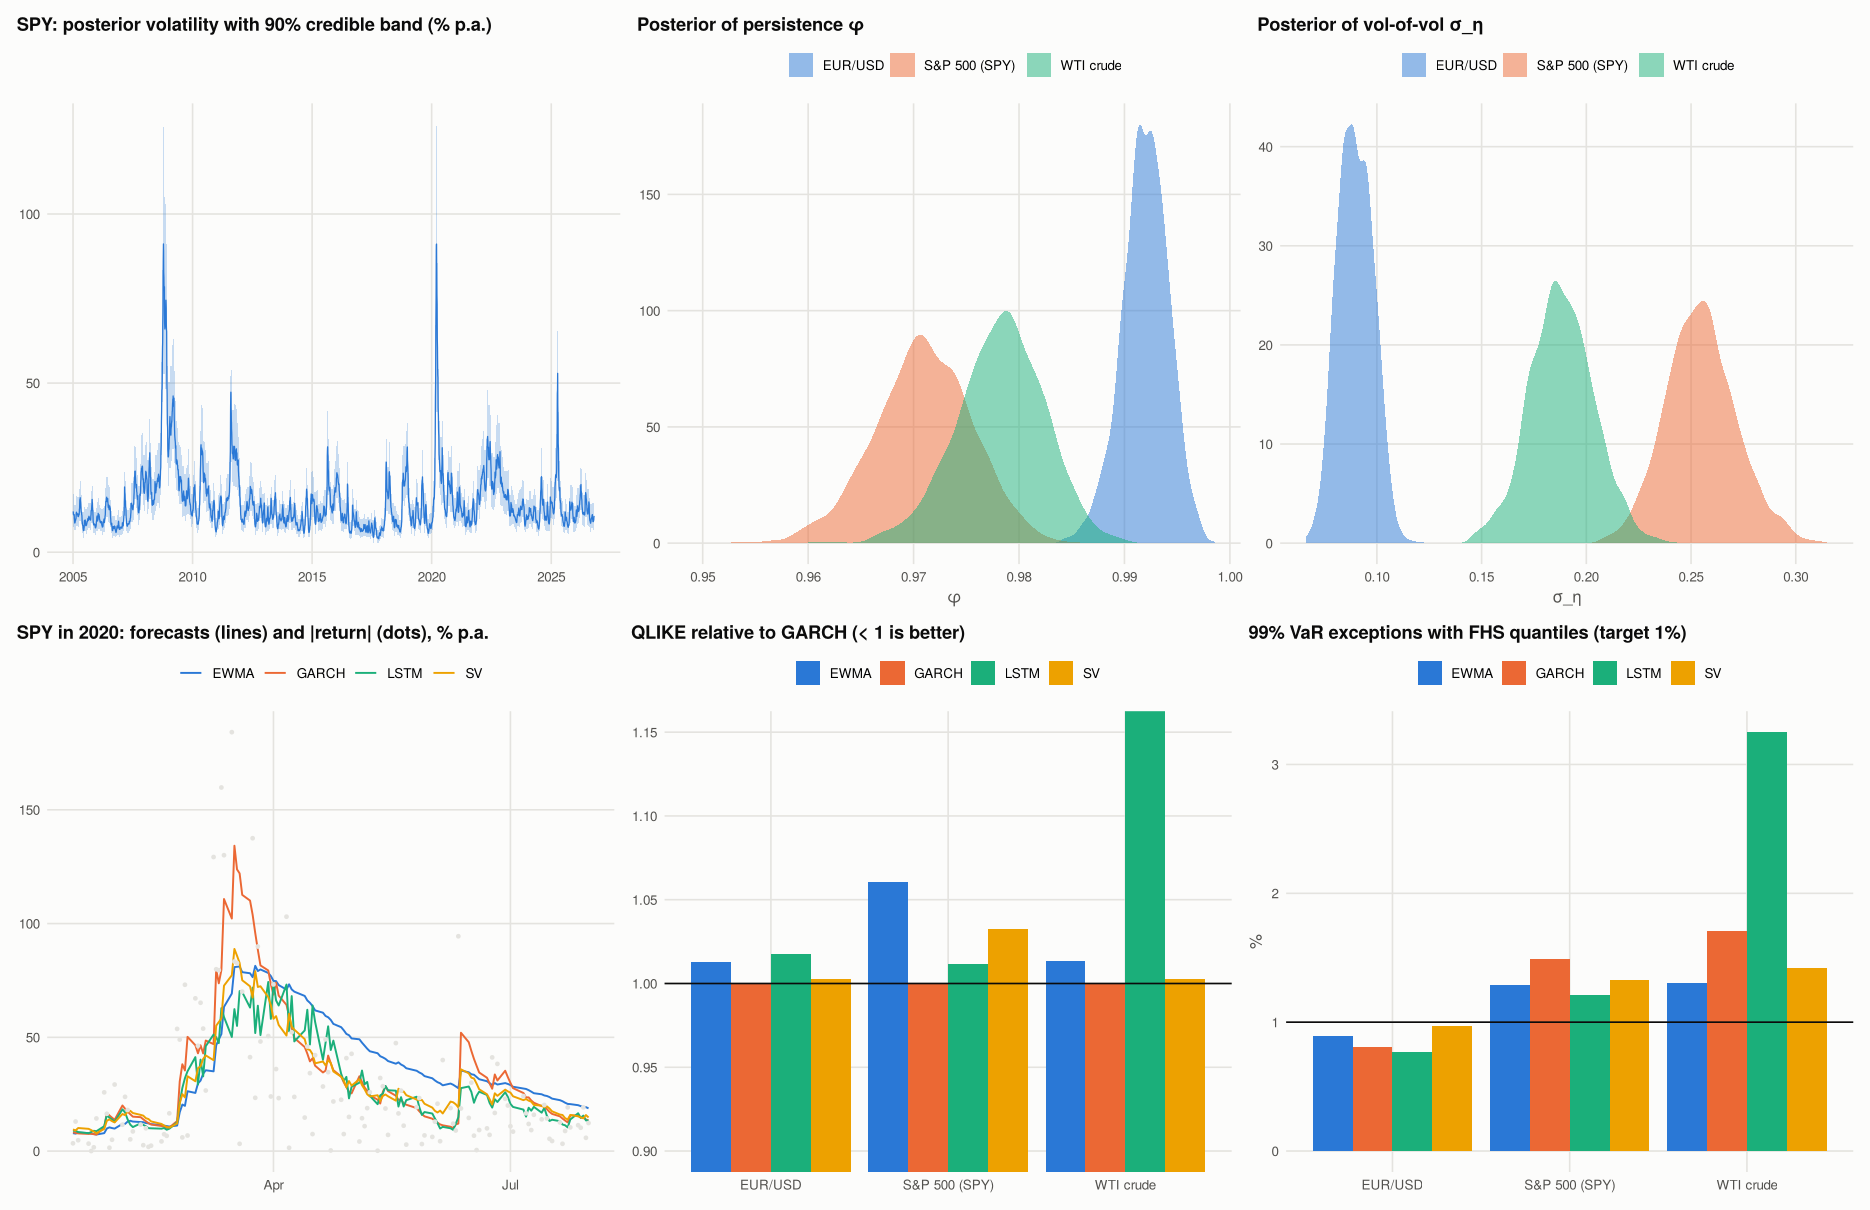

In [7]:
options(repr.plot.width = 17, repr.plot.height = 11)
lat <- as.matrix(SVF[[1]]$latent[[1]])
band <- tibble(
  date = index(RET[[1]]), lo = exp(apply(lat, 2, quantile, 0.05) / 2) *
    sqrt(252), med = exp(apply(lat, 2, median) / 2) * sqrt(252),
  hi = exp(apply(lat, 2, quantile, 0.95) / 2) * sqrt(252)
)
p1 <- ggplot(band, aes(date)) +
  geom_ribbon(aes(ymin = lo, ymax = hi), fill = PALETTE[1], alpha = 0.25) +
  geom_line(aes(y = med), colour = PALETTE[1], linewidth = 0.4) +
  labs(
    title = "SPY: posterior volatility with 90% credible band (% p.a.)",
    x = NULL, y = NULL
  )
pp <- imap_dfr(SVF, function(f, a) as_tibble(post(f)) |> mutate(asset = a))
p2 <- ggplot(pp, aes(phi, fill = asset)) +
  geom_density(alpha = 0.5, colour = NA) +
  scale_fill_manual(values = PALETTE[1:3]) +
  labs(title = "Posterior of persistence φ", x = "φ", y = NULL)
p3 <- ggplot(pp, aes(sigma, fill = asset)) +
  geom_density(alpha = 0.5, colour = NA) +
  scale_fill_manual(values = PALETTE[1:3]) +
  labs(title = "Posterior of vol-of-vol σ_η", x = "σ_η", y = NULL)
z20 <- FC[[1]] |>
  filter(date >= as.Date("2020-01-15"), date <= as.Date("2020-07-31")) |>
  pivot_longer(all_of(MODS)) |>
  mutate(vol = sqrt(value * 252))
p4 <- ggplot(z20, aes(date, vol, colour = name)) +
  geom_line(linewidth = 0.6) +
  geom_point(
    data = FC[[1]] |>
      filter(date >= as.Date("2020-01-15"), date <= as.Date("2020-07-31")),
    aes(date, abs(r) * sqrt(252)), inherit.aes = FALSE, colour = GRID,
    size = 0.8
  ) +
  scale_colour_manual(values = PALETTE[1:4]) +
  labs(
    title = "SPY in 2020: forecasts (lines) and |return| (dots), % p.a.",
    x = NULL, y = NULL
  )
p5 <- SCORE |>
  group_by(asset) |>
  mutate(rel = QLIKE / QLIKE[model == "GARCH"]) |>
  ggplot(aes(asset, rel, fill = model)) +
  geom_col(position = "dodge") +
  geom_hline(yintercept = 1, colour = INK) +
  coord_cartesian(ylim = c(0.9, 1.15)) +
  scale_fill_manual(values = PALETTE[1:4]) +
  labs(title = "QLIKE relative to GARCH (< 1 is better)", x = NULL, y = NULL)
p6 <- SCORE |> ggplot(aes(asset, `VaR99 FHS: exceptions (%)`, fill = model)) +
  geom_col(position = "dodge") +
  geom_hline(yintercept = 1, colour = INK) +
  scale_fill_manual(values = PALETTE[1:4]) +
  labs(
    title = "99% VaR exceptions with FHS quantiles (target 1%)", x = NULL,
    y = "%"
  )
p <- (p1 | p2 | p3) / (p4 | p5 | p6)
save_fig(p, "01_sv_garch_lstm", width = 18, height = 11)
print(p)

In [8]:
d1 <- plot_ly(band, x = ~date) |>
  add_ribbons(
    ymin = ~lo, ymax = ~hi, name = "90% band",
    fillcolor = "rgba(42,120,214,0.25)", line = list(width = 0)
  ) |>
  add_lines(
    y = ~med, name = "posterior median",
    line = list(color = PALETTE[1], width = 1)
  )
d2 <- plot_ly(SCORE,
  x = ~asset, y = ~QLIKE, color = ~model,
  colors = PALETTE[1:4], type = "bar"
)
z_last <- FC[[1]] |>
  tail(500) |>
  pivot_longer(all_of(MODS)) |>
  mutate(vol = sqrt(value * 252))
d3 <- plot_ly(z_last,
  x = ~date, y = ~vol, color = ~name,
  colors = PALETTE[1:4], type = "scatter", mode = "lines"
)
d4 <- plot_ly(SCORE,
  x = ~asset, y = ~`VaR99 FHS: exceptions (%)`,
  color = ~model, colors = PALETTE[1:4], type = "bar"
)
dash <- subplot(d1, d2, d3, d4, nrows = 2, margin = 0.07) |>
  layout(
    title = "Stochastic volatility vs GARCH vs LSTM",
    paper_bgcolor = SURFACE, plot_bgcolor = SURFACE
  )
save_plotly_html(dash, "dashboard", "SV vs GARCH vs LSTM")
save_fig((p1 | p5) / (p4 | p6), "dashboard", width = 15, height = 10)

Dashboard saved: outputs/dashboard.html



## 8. Reading the results and limitations

**GJR-GARCH wins.** On out-of-sample QLIKE from 2012, GJR-GARCH with Student-t errors is the best of the four models for all three assets: 1.562 for the S&P 500, 1.476 for EUR/USD and 1.533 for WTI.
- **Stochastic volatility** is a close second for the euro and oil; the Diebold–Mariano statistics against GARCH (−1.0 and −0.3) are not significant. It is significantly worse for the S&P 500 (DM −2.6).
  - The reason is the leverage effect. Equity volatility jumps after falls, and GJR-GARCH has a term for exactly that. The SV model estimated here is symmetric.
  - Currencies show little asymmetry, so there the two models are almost equivalent.
- **The LSTM** is not significantly worse than GARCH for the S&P 500 (DM −0.9). It even wins 8 of the 15 calendar years there, but loses heavily in a few turbulent years.
  - For EUR/USD (DM −2.2) and crude oil (QLIKE 1.88 against 1.53, DM −2.5) it is clearly worse. A neural network trained on a few thousand noisy daily returns struggles to beat a three-parameter recursion built for exactly this problem.
- **EWMA** (RiskMetrics) is the worst or second worst everywhere: one fixed decay cannot fit three very different assets.

**The SV posteriors describe the assets.**
- Volatility persistence φ is 0.971 for the S&P 500, 0.978 for oil and 0.992 for the euro. That gives half-lives of 24, 32 and 87 days: equity volatility shocks fade within a month, currency volatility regimes last a quarter or more.
- The volatility of volatility σ_η is three times larger for the S&P 500 (0.25) than for the euro (0.09).
- The 90% credible intervals are narrow, so twenty years of data identify these parameters well.

**For VaR, the tails matter more than the model.**
- With normal quantiles (2.33 σ), every model breaches its 99% VaR on 1.3–2.4% of days instead of 1%.
- Filtered historical simulation uses the empirical quantile of standardised returns. It brings most models to 0.8–1.5% on the S&P 500 and the euro.
- Oil remains hard: GARCH-FHS still breaches on 1.7% of days, and the LSTM on 3.3%, its worst result.

**Limitations.**
- The SV model has no leverage term or fat-tailed errors. `stochvol` supports both, and adding them would probably close the gap on equities, at a higher MCMC cost.
- Re-estimation is periodic (SV every 126 days, GARCH 63, LSTM 252), not daily.
- Forecasts are one day ahead only; multi-day horizons could rank the models differently.
- The LSTM has one fixed architecture, chosen before the test. A larger network or more inputs (implied volatility, intraday ranges) could do better.
- Diebold–Mariano tests on overlapping assets and years are not independent of each other.

In [9]:
write_csv(SV_TAB, file.path(OUT_DIR, "sv_posterior_summary.csv"))
write_csv(SCORE, file.path(OUT_DIR, "forecast_scores.csv"))
write_csv(WIN, file.path(OUT_DIR, "years_won_by_model.csv"))
write_csv(YR, file.path(OUT_DIR, "qlike_by_year.csv"))
write_csv(
  imap_dfr(FC, function(f, a) mutate(f, asset = a)),
  file.path(OUT_DIR, "daily_variance_forecasts.csv")
)
cat(
  "Outputs written:", paste(sort(list.files(OUT_DIR)), collapse = ", "),
  "\n"
)

Outputs written: 01_sv_garch_lstm.png, daily_variance_forecasts.csv, dashboard.html, dashboard.png, forecast_scores.csv, qlike_by_year.csv, sv_posterior_summary.csv, years_won_by_model.csv 


## References

### Finance and regulation

- Jacquier, E., Polson, N. G., & Rossi, P. E. (1994). Bayesian analysis of stochastic volatility models. *Journal of Business & Economic Statistics, 12*(4), 371–389. https://doi.org/10.1080/07350015.1994.10524553
- Glosten, L. R., Jagannathan, R., & Runkle, D. E. (1993). On the relation between the expected value and the volatility of the nominal excess return on stocks. *The Journal of Finance, 48*(5), 1779–1801. https://doi.org/10.1111/j.1540-6261.1993.tb05128.x
- Patton, A. J. (2011). Volatility forecast comparison using imperfect volatility proxies. *Journal of Econometrics, 160*(1), 246–256. https://doi.org/10.1016/j.jeconom.2010.03.034
- Diebold, F. X., & Mariano, R. S. (1995). Comparing predictive accuracy. *Journal of Business & Economic Statistics, 13*(3), 253–263. https://doi.org/10.1080/07350015.1995.10524599
- Kupiec, P. H. (1995). Techniques for verifying the accuracy of risk measurement models. *The Journal of Derivatives, 3*(2), 73–84. https://doi.org/10.3905/jod.1995.407942

### Machine learning and deep learning

- Kastner, G. (2016). Dealing with stochastic volatility in time series using the R package stochvol. *Journal of Statistical Software, 69*(5), 1–30. https://doi.org/10.18637/jss.v069.i05
- Gordon, N. J., Salmond, D. J., & Smith, A. F. M. (1993). Novel approach to nonlinear/non-Gaussian Bayesian state estimation. *IEE Proceedings F, 140*(2), 107–113. https://doi.org/10.1049/ip-f-2.1993.0015
- Hochreiter, S., & Schmidhuber, J. (1997). Long short-term memory. *Neural Computation, 9*(8), 1735–1780. https://doi.org/10.1162/neco.1997.9.8.1735